# Simulación y probabilidad · Paseos aleatorios y cadenas de Markov

Un paseo aleatorio suma pasos independientes, $S_n = X_1 + \dots + X_n$: con pasos de $\pm 1$ equiprobables, $E[S_n] = 0$ y $E[S_n^2] = n$, así que se aleja del origen como $\sqrt n$. Una cadena de Markov salta entre estados con probabilidades que solo dependen del estado actual, $P_{ij} = P(X_{t+1} = j \mid X_t = i)$; la distribución tras $n$ pasos es $p_n = p_0 P^n$ y, si la cadena es irreducible y aperiódica, tiende a la distribución estacionaria $\pi = \pi P$. Simular $m$ paseos de $n$ pasos con `numpy` cuesta $O(mn)$, y calcular $P^n$ por cuadrados sucesivos, $O(k^3 \log n)$ con $k$ estados. Las semillas son fijas para que los resultados se puedan reproducir.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

## 1. Paseo aleatorio en una dimensión

Simular 2000 paseos de 1000 pasos de $\pm 1$ con `numpy` (`cumsum`), dibujar 10 de ellos junto a las curvas $\pm 2\sqrt n$ y comprobar que la media de $S_n$ se mantiene cerca de 0 y la de $S_n^2$, cerca de $n$.

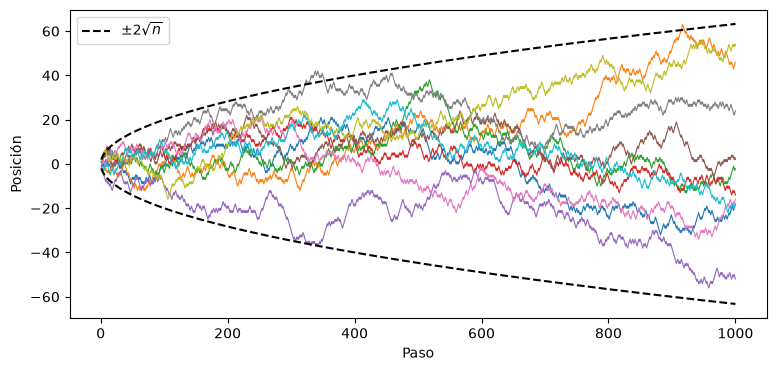

Tras 1000 pasos: media -0.35, media de S² 1032
Paseos dentro de ±2√n al final: 94.8%


In [2]:
rng = np.random.default_rng(1)
posiciones = np.cumsum(rng.choice([-1, 1], size=(2000, 1000)), axis=1)
n = np.arange(1, 1001)

plt.figure(figsize=(9, 4))
plt.plot(n, posiciones[:10].T, linewidth=0.8)
plt.plot(n, 2 * np.sqrt(n), "k--", label=r"$\pm 2\sqrt{n}$")
plt.plot(n, -2 * np.sqrt(n), "k--")
plt.xlabel("Paso")
plt.ylabel("Posición")
plt.legend()
plt.show()

media, media_cuadrado = posiciones.mean(axis=0), (posiciones**2).mean(axis=0)
print(f"Tras 1000 pasos: media {media[-1]:.2f}, media de S² {media_cuadrado[-1]:.0f}")
print(f"Paseos dentro de ±2√n al final: {np.mean(np.abs(posiciones[:, -1]) <= 2 * math.sqrt(1000)):.1%}")
assert np.all(np.abs(media) < 4 * np.sqrt(n / 2000))
assert np.all(np.abs(media_cuadrado / n - 1) < 0.15)

## 2. Paseo aleatorio en el plano

En cada paso moverse una unidad al norte, al sur, al este o al oeste. Dibujar tres paseos de 5000 pasos y, con 2000 paseos de 1000 pasos, comprobar que la distancia cuadrática media al origen es $E[R_n^2] = n$, dibujándola frente a $n$.

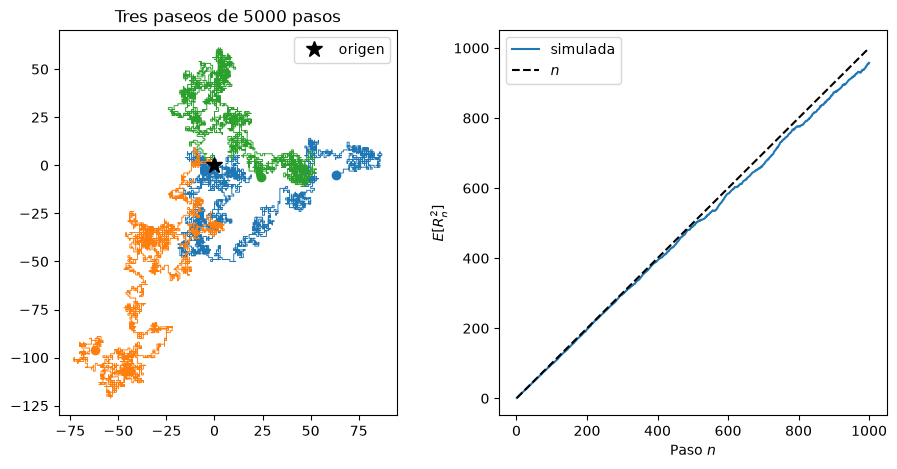

E[R²] tras 1000 pasos: 957


In [3]:
direcciones = np.array([(1, 0), (-1, 0), (0, 1), (0, -1)])


def paseo_2d(paseos, pasos, rng):
    return np.cumsum(direcciones[rng.integers(4, size=(paseos, pasos))], axis=1)


rng = np.random.default_rng(2)
fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(11, 5))
for x, y in paseo_2d(3, 5000, rng).transpose(0, 2, 1):
    eje1.plot(x, y, linewidth=0.7)
    eje1.plot(x[-1], y[-1], "o", color=eje1.lines[-1].get_color())
eje1.plot(0, 0, "k*", markersize=12, label="origen")
eje1.set_aspect("equal")
eje1.legend()
eje1.set_title("Tres paseos de 5000 pasos")

posiciones = paseo_2d(2000, 1000, rng)
r2 = (posiciones**2).sum(axis=2).mean(axis=0)
n = np.arange(1, 1001)
eje2.plot(n, r2, label="simulada")
eje2.plot(n, n, "k--", label="$n$")
eje2.set_xlabel("Paso $n$")
eje2.set_ylabel("$E[R_n^2]$")
eje2.legend()
plt.show()
print(f"E[R²] tras 1000 pasos: {r2[-1]:.0f}")
assert np.all(np.abs(r2 / n - 1) < 0.1)

## 3. Tiempo de retorno al origen

En una dimensión el paseo vuelve al origen con probabilidad 1, pero el tiempo medio de retorno es infinito: la probabilidad de no haber vuelto tras $2n$ pasos, $P(T > 2n) = \binom{2n}{n} 4^{-n} \approx \frac{1}{\sqrt{\pi n}}$, decrece muy despacio. Simular 5000 paseos de 4000 pasos, calcular el primer retorno de cada uno, comparar la fracción que aún no ha vuelto con la fórmula y ver que la media de los tiempos observados crece con el horizonte de la simulación.

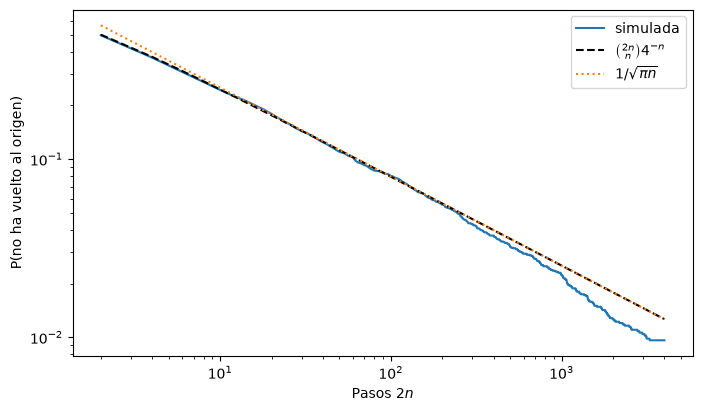

Mediana del tiempo de retorno: 2 pasos
Vuelven antes de  100: 92.0%, tiempo medio    8.5
Vuelven antes de 1000: 97.8%, tiempo medio   26.3
Vuelven antes de 4000: 99.0%, tiempo medio   47.5


In [4]:
rng = np.random.default_rng(3)
paseos, pasos = 5000, 4000
posiciones = np.cumsum(rng.choice(np.array([-1, 1], dtype=np.int8), size=(paseos, pasos)), axis=1, dtype=np.int16)
en_origen = posiciones == 0
retorno = np.where(en_origen.any(axis=1), en_origen.argmax(axis=1) + 1, np.inf)

t = np.arange(2, pasos + 1, 2)
simulada = 1 - np.searchsorted(np.sort(retorno), t, side="right") / paseos
mitades = np.arange(1, pasos // 2 + 1)
exacta = np.cumprod((2 * mitades - 1) / (2 * mitades))
assert np.abs(simulada - exacta).max() < 0.02

plt.figure(figsize=(8, 4.5))
plt.loglog(t, simulada, label="simulada")
plt.loglog(t, exacta, "k--", label=r"$\binom{2n}{n}4^{-n}$")
plt.loglog(t, 1 / np.sqrt(math.pi * t / 2), ":", label=r"$1/\sqrt{\pi n}$")
plt.xlabel("Pasos $2n$")
plt.ylabel("P(no ha vuelto al origen)")
plt.legend()
plt.show()

print(f"Mediana del tiempo de retorno: {np.median(retorno):.0f} pasos")
for horizonte in (100, 1000, 4000):
    vueltos = retorno[retorno <= horizonte]
    print(f"Vuelven antes de {horizonte:4}: {len(vueltos) / paseos:.1%}, tiempo medio {vueltos.mean():6.1f}")

## 4. ¿Vuelve siempre? El teorema de Pólya

El paseo aleatorio simple vuelve al origen con probabilidad 1 en una y dos dimensiones, pero no en tres, donde solo vuelve con probabilidad $\approx 0{,}34$. Simular 2000 paseos de 5000 pasos en $d = 1, 2, 3$ (en cada paso se elige un eje y un sentido) y dibujar la fracción que ya ha vuelto al origen frente al número de pasos.

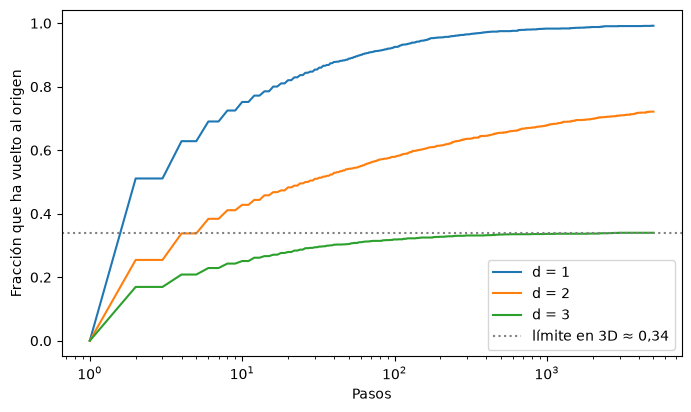

d = 1: 99.2% han vuelto en 5000 pasos
d = 2: 72.2% han vuelto en 5000 pasos
d = 3: 34.0% han vuelto en 5000 pasos


In [5]:
def primer_retorno(d, paseos, pasos, rng):
    eje = rng.integers(d, size=(paseos, pasos))
    signo = rng.choice(np.array([-1, 1], dtype=np.int8), size=(paseos, pasos))
    en_origen = np.ones((paseos, pasos), dtype=bool)
    for k in range(d):
        en_origen &= np.cumsum(np.where(eje == k, signo, 0), axis=1, dtype=np.int16) == 0
    return np.where(en_origen.any(axis=1), en_origen.argmax(axis=1) + 1, np.inf)


rng = np.random.default_rng(4)
paseos, pasos = 2000, 5000
t = np.arange(1, pasos + 1)
finales = {}
plt.figure(figsize=(8, 4.5))
for d in (1, 2, 3):
    retorno = np.sort(primer_retorno(d, paseos, pasos, rng))
    fraccion = np.searchsorted(retorno, t, side="right") / paseos
    finales[d] = fraccion[-1]
    plt.plot(t, fraccion, label=f"d = {d}")
plt.axhline(0.3405, color="gray", linestyle=":", label="límite en 3D ≈ 0,34")
plt.xscale("log")
plt.xlabel("Pasos")
plt.ylabel("Fracción que ha vuelto al origen")
plt.legend()
plt.show()
for d, f in finales.items():
    print(f"d = {d}: {f:.1%} han vuelto en {pasos} pasos")
assert finales[1] > finales[2] > finales[3] and finales[1] > 0.97 and finales[3] < 0.37

## 5. Cadena de Markov del tiempo

Modelar el tiempo de un pueblo de Canarias con tres estados, soleado, nublado y lluvia, y una matriz de transición de ejemplo (no medida): tras un día soleado lo más probable es otro soleado y la lluvia dura poco. Crear `CadenaMarkov(estados, P)` que valide la matriz (cuadrada, no negativa y con filas que suman 1) y tenga `simular(inicial, pasos, rng)` y `distribucion(inicial, n)`, que calcula $p_0 P^n$ a partir de un estado o de un vector. Simular dos semanas, calcular la probabilidad de cada tiempo dentro de 1, 2 y 7 días si hoy llueve y comprobar `distribucion` sumando todos los caminos posibles.

In [6]:
import random
from bisect import bisect_right
from itertools import product


class CadenaMarkov:
    def __init__(self, estados, P):
        self.estados = list(estados)
        self.P = np.asarray(P, dtype=float)
        k = len(self.estados)
        if self.P.shape != (k, k) or (self.P < 0).any() or not np.allclose(self.P.sum(axis=1), 1):
            raise ValueError("la matriz de transición no es válida")
        self.indice = {e: i for i, e in enumerate(self.estados)}
        self.acumulada = np.cumsum(self.P, axis=1).tolist()

    def _vector(self, inicial):
        if isinstance(inicial, str):
            return np.eye(len(self.estados))[self.indice[inicial]]
        return np.asarray(inicial, dtype=float)

    def distribucion(self, inicial, n):
        return self._vector(inicial) @ np.linalg.matrix_power(self.P, n)

    def simular(self, inicial, pasos, rng):
        i = self.indice[inicial]
        recorrido = [inicial]
        for u in rng.random(pasos):
            i = min(bisect_right(self.acumulada[i], u), len(self.estados) - 1)
            recorrido.append(self.estados[i])
        return recorrido


def distribucion_fuerza_bruta(cadena, inicial, n):
    resultado = np.zeros(len(cadena.estados))
    for camino in product(range(len(cadena.estados)), repeat=n):
        probabilidad, i = 1.0, cadena.indice[inicial]
        for j in camino:
            probabilidad *= cadena.P[i, j]
            i = j
        resultado[i] += probabilidad
    return resultado


tiempo = CadenaMarkov(
    ["soleado", "nublado", "lluvia"],
    [[0.75, 0.20, 0.05],
     [0.40, 0.45, 0.15],
     [0.30, 0.45, 0.25]],
)
try:
    CadenaMarkov(["a", "b"], [[0.5, 0.6], [1, 0]])
except ValueError as e:
    print("Error:", e)

rng = np.random.default_rng(5)
print("Dos semanas:", ", ".join(tiempo.simular("soleado", 14, rng)))
for n in (1, 2, 7):
    p = tiempo.distribucion("lluvia", n)
    print(f"Si hoy llueve, dentro de {n} día{'s' if n > 1 else ''}: " + ", ".join(f"{e} {x:.3f}" for e, x in zip(tiempo.estados, p)))

for inicial in tiempo.estados:
    for n in range(6):
        assert np.allclose(tiempo.distribucion(inicial, n), distribucion_fuerza_bruta(tiempo, inicial, n))
print("Comprobación correcta")

Error: la matriz de transición no es válida
Dos semanas: soleado, nublado, nublado, nublado, soleado, soleado, soleado, soleado, soleado, soleado, lluvia, nublado, soleado, soleado, lluvia
Si hoy llueve, dentro de 1 día: soleado 0.300, nublado 0.450, lluvia 0.250
Si hoy llueve, dentro de 2 días: soleado 0.480, nublado 0.375, lluvia 0.145
Si hoy llueve, dentro de 7 días: soleado 0.599, nublado 0.301, lluvia 0.100
Comprobación correcta


## 6. Distribución estacionaria con potencias de la matriz

Si la cadena es irreducible y aperiódica, todas las filas de $P^n$ tienden a la distribución estacionaria $\pi$, que cumple $\pi = \pi P$ y $\sum_i \pi_i = 1$. Calcularla con `np.linalg.matrix_power`, comprobarla resolviendo el sistema lineal y con el vector propio de $P^T$ de valor propio 1, y dibujar cómo la distancia entre $p_0 P^n$ y $\pi$ cae geométricamente, al ritmo del segundo valor propio, $|\lambda_2|^n$.

P^50 =
[[0.6 0.3 0.1]
 [0.6 0.3 0.1]
 [0.6 0.3 0.1]]
Estacionaria: soleado 0.6000, nublado 0.3000, lluvia 0.1000


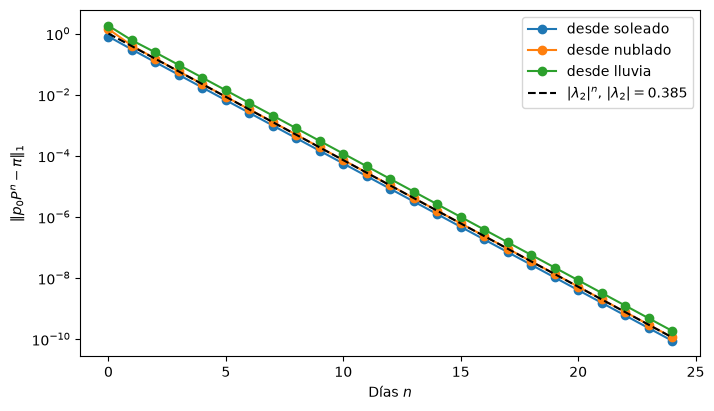

In [7]:
def estacionaria_sistema(P):
    k = len(P)
    A = np.vstack([P.T - np.eye(k), np.ones(k)])
    b = np.zeros(k + 1)
    b[-1] = 1
    return np.linalg.lstsq(A, b, rcond=None)[0]


def estacionaria_vector_propio(P):
    valores, vectores = np.linalg.eig(P.T)
    v = np.real(vectores[:, np.argmin(np.abs(valores - 1))])
    return v / v.sum()


potencia = np.linalg.matrix_power(tiempo.P, 50)
estacionaria = potencia[0]
print("P^50 =")
print(potencia.round(4))


def mostrar(nombre, p):
    print(f"{nombre:13}", ", ".join(f"{e} {x:.4f}" for e, x in zip(tiempo.estados, p)))


mostrar("Estacionaria:", estacionaria)
assert np.allclose(potencia, estacionaria)
assert np.allclose(estacionaria @ tiempo.P, estacionaria)
assert np.allclose(estacionaria, estacionaria_sistema(tiempo.P))
assert np.allclose(estacionaria, estacionaria_vector_propio(tiempo.P))

lambda2 = sorted(np.abs(np.linalg.eigvals(tiempo.P)))[-2]
n = np.arange(25)
plt.figure(figsize=(8, 4.5))
for estado in tiempo.estados:
    plt.semilogy(n, [np.abs(tiempo.distribucion(estado, k) - estacionaria).sum() for k in n], "o-", label=f"desde {estado}")
plt.semilogy(n, lambda2**n, "k--", label=rf"$|\lambda_2|^n$, $|\lambda_2| = {lambda2:.3f}$")
plt.xlabel("Días $n$")
plt.ylabel(r"$\|p_0 P^n - \pi\|_1$")
plt.legend()
plt.show()

## 7. Distribución estacionaria por simulación

Por el teorema ergódico, la fracción de días que la cadena pasa en cada estado tiende a $\pi$ sea cual sea el estado inicial. Simular $2 \cdot 10^5$ días, dibujar la frecuencia acumulada de cada estado frente a la estacionaria y estimar la matriz $P$ contando las transiciones observadas.

Frecuencias:  soleado 0.6013, nublado 0.2994, lluvia 0.0993
Estacionaria: soleado 0.6000, nublado 0.3000, lluvia 0.1000
P estimada:
[[0.75  0.201 0.049]
 [0.403 0.448 0.149]
 [0.301 0.449 0.251]]


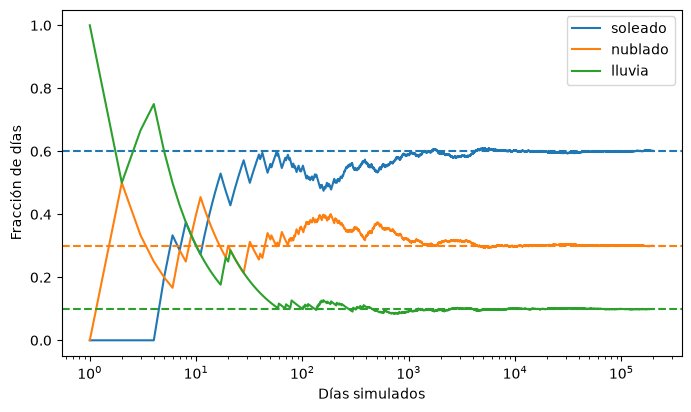

In [8]:
rng = np.random.default_rng(7)
recorrido = np.array([tiempo.indice[e] for e in tiempo.simular("lluvia", 200_000, rng)])
dias = np.arange(1, len(recorrido) + 1)
acumuladas = np.cumsum(np.eye(3)[recorrido], axis=0) / dias[:, None]

conteo = np.zeros((3, 3))
np.add.at(conteo, (recorrido[:-1], recorrido[1:]), 1)
P_estimada = conteo / conteo.sum(axis=1, keepdims=True)
mostrar("Frecuencias:", acumuladas[-1])
mostrar("Estacionaria:", estacionaria)
print("P estimada:")
print(P_estimada.round(3))
assert np.abs(acumuladas[-1] - estacionaria).max() < 0.01
assert np.abs(P_estimada - tiempo.P).max() < 0.01

plt.figure(figsize=(8, 4.5))
for k, estado in enumerate(tiempo.estados):
    plt.plot(dias, acumuladas[:, k], label=estado)
    plt.axhline(estacionaria[k], color=plt.gca().lines[-1].get_color(), linestyle="--")
plt.xscale("log")
plt.xlabel("Días simulados")
plt.ylabel("Fracción de días")
plt.legend()
plt.show()

## 8. Generador de texto

Una cadena de Markov de orden $k$ sobre palabras elige la siguiente palabra según las $k$ anteriores, con las frecuencias vistas en un texto. Crear `GeneradorTexto(orden)` con `entrenar(texto)`, que guarde para cada tupla de $k$ palabras la lista de las que la siguen, y `generar(n, rng)`, que empiece en una palabra con mayúscula. Entrenarlo con el texto de la celda (escrito para este ejercicio), generar frases de orden 1 y 2 y comprobar que cada grupo de $k+1$ palabras seguidas del resultado aparece en el texto.

In [9]:
from collections import defaultdict

texto = '''
Por la mañana el mar está tranquilo y el sol sale detrás de la montaña. En el puerto los barcos salen a pescar
y en el pueblo abren las tiendas. La guagua sube al pueblo llena de gente y baja a la playa llena de niños.
En la playa el sol calienta la arena y el mar trae una brisa suave. Por la tarde las nubes llegan del norte y
se quedan en la montaña. En la montaña llueve un poco y el agua baja por el barranco hasta el mar. En el pueblo
la gente habla del tiempo, del mar y de la guagua. Cuando llueve en la montaña, el barranco se llena de agua y
los niños miran el agua desde el puente. Cuando sale el sol, la gente vuelve a la playa y los barcos vuelven al
puerto. Por la noche el mar está tranquilo, el pueblo duerme y la guagua espera en la plaza a que salga el sol.
'''


class GeneradorTexto:
    def __init__(self, orden=1):
        self.orden = orden
        self.siguientes = defaultdict(list)

    def entrenar(self, texto):
        palabras = texto.split()
        for i in range(len(palabras) - self.orden):
            self.siguientes[tuple(palabras[i:i + self.orden])].append(palabras[i + self.orden])
        return self

    def generar(self, n, rng):
        estado = rng.choice([e for e in self.siguientes if e[0][0].isupper()])
        palabras = list(estado)
        while len(palabras) < n and estado in self.siguientes:
            palabras.append(rng.choice(self.siguientes[estado]))
            estado = tuple(palabras[-self.orden:])
        return " ".join(palabras)


def grupos(palabras, k):
    return {tuple(palabras[i:i + k]) for i in range(len(palabras) - k + 1)}


rng = random.Random(8)
grupos_texto = {k: grupos(texto.split(), k) for k in (2, 3)}
for orden in (1, 2):
    generador = GeneradorTexto(orden).entrenar(texto)
    variados = sorted(generador.siguientes, key=lambda e: -len(set(generador.siguientes[e])))[:4]
    print(f"Orden {orden}: {len(generador.siguientes)} estados; con más continuaciones distintas:",
          ", ".join(" ".join(e) for e in variados))
    for _ in range(3):
        frase = generador.generar(25, rng)
        print("  ", frase)
        assert grupos(frase.split(), orden + 1) <= grupos_texto[orden + 1]
print("Comprobación correcta")

Orden 1: 76 estados; con más continuaciones distintas: la, el, y, de
   En la playa llena de la playa llena de agua baja por el mar está tranquilo, el pueblo llena de la plaza a pescar y
   Cuando sale el pueblo la playa llena de agua y en el barranco hasta el pueblo llena de gente vuelve a pescar y el sol
   Cuando sale el agua y baja a pescar y el pueblo llena de gente habla del mar está tranquilo y el mar y el barranco
Orden 2: 134 estados; con más continuaciones distintas: Por la, y el, el pueblo, llena de
   La guagua sube al pueblo llena de agua y los barcos salen a pescar y en el pueblo abren las tiendas. La guagua sube al
   En la montaña llueve un poco y el agua baja por el barranco se llena de agua y los niños miran el agua desde el
   Cuando sale el sol, la gente habla del tiempo, del mar y de la guagua. Cuando llueve en la plaza a que salga el sol.
Comprobación correcta


## 9. Cadena absorbente: serpientes y escaleras

En un tablero de 20 casillas se sale de la 0 y se avanza lo que marque un dado; algunas casillas tienen una escalera (suben) o una serpiente (bajan), y hay que llegar justo a la 20 (si se pasa, no se mueve). La meta es un estado absorbente: si $Q$ es la parte de $P$ entre estados no absorbentes, la matriz fundamental $N = (I - Q)^{-1}$ da el número esperado de tiradas desde cada casilla, $t = N\mathbf{1}$. Construir la matriz, calcular el número medio de tiradas desde la salida, compararlo con $10^4$ partidas simuladas y dibujar la distribución exacta del número de tiradas, $P(T = n) = (p_0 P^n)_{20} - (p_0 P^{n-1})_{20}$, sobre el histograma.

Tiradas esperadas desde la salida: 12.930
Media simulada: 12.917 ± 0.102


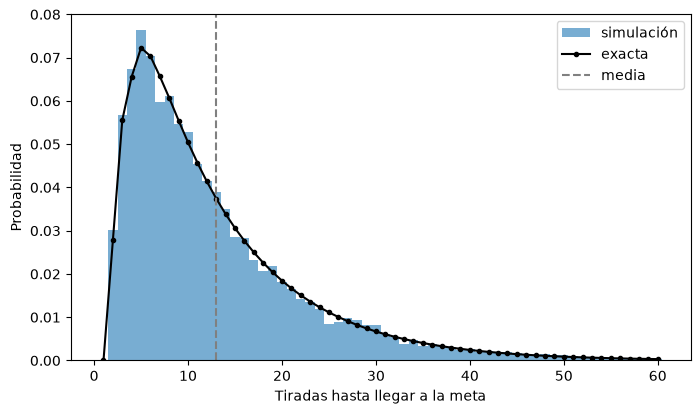

In [10]:
casillas = 20
saltos = {3: 11, 6: 14, 9: 17, 13: 4, 16: 7, 19: 8}


def matriz_tablero(casillas, saltos):
    P = np.zeros((casillas + 1, casillas + 1))
    for casilla in range(casillas):
        for dado in range(1, 7):
            destino = casilla + dado if casilla + dado <= casillas else casilla
            P[casilla, saltos.get(destino, destino)] += 1 / 6
    P[casillas, casillas] = 1
    return P


def partida(rng):
    casilla = tiradas = 0
    while casilla != casillas:
        tiradas += 1
        destino = casilla + rng.randint(1, 6)
        if destino <= casillas:
            casilla = saltos.get(destino, destino)
    return tiradas


P = matriz_tablero(casillas, saltos)
Q = P[:-1, :-1]
N = np.linalg.inv(np.eye(casillas) - Q)
esperadas = N.sum(axis=1)

rng = random.Random(9)
tiradas = np.array([partida(rng) for _ in range(10_000)])
error = tiradas.std(ddof=1) / math.sqrt(len(tiradas))
print(f"Tiradas esperadas desde la salida: {esperadas[0]:.3f}")
print(f"Media simulada: {tiradas.mean():.3f} ± {error:.3f}")
assert abs(tiradas.mean() - esperadas[0]) < 4 * error

terminada, p = [0.0], np.eye(casillas + 1)[0]
for _ in range(400):
    p = p @ P
    terminada.append(p[-1])
probabilidad = np.diff(terminada)
assert abs((np.arange(1, 401) * probabilidad).sum() - esperadas[0]) < 1e-6

plt.figure(figsize=(8, 4.5))
plt.hist(tiradas, bins=np.arange(0.5, 61.5), density=True, alpha=0.6, label="simulación")
plt.plot(np.arange(1, 61), probabilidad[:60], "k.-", label="exacta")
plt.axvline(esperadas[0], color="gray", linestyle="--", label="media")
plt.xlabel("Tiradas hasta llegar a la meta")
plt.ylabel("Probabilidad")
plt.legend()
plt.show()

## 10. Colas con `simpy`

A una oficina llegan clientes al azar a un ritmo de $\lambda$ por minuto (tiempos entre llegadas exponenciales) y cada uno de los $c$ empleados atiende en un tiempo exponencial de media $1/\mu$. Con un solo empleado (cola M/M/1) la espera media en la cola es $W_q = \frac{\lambda}{\mu(\mu - \lambda)}$, y con $c$ empleados es $W_q = \frac{C(c, a)}{c\mu - \lambda}$, donde $a = \lambda/\mu$ y $C(c, a)$ es la probabilidad de tener que esperar (fórmula de Erlang C). Simular la oficina con `simpy.Resource`, comprobar la fórmula de la M/M/1 con $\lambda = 0{,}8$ y $\mu = 1$, y con $\lambda = 1{,}5$ dibujar la longitud de la cola con 1, 2 y 3 empleados (con uno solo crece sin parar) y comparar la espera media simulada con la teórica para 2, 3 y 4 empleados.

M/M/1: espera media simulada 3.952 min, teórica 4.000 min (72281 clientes)


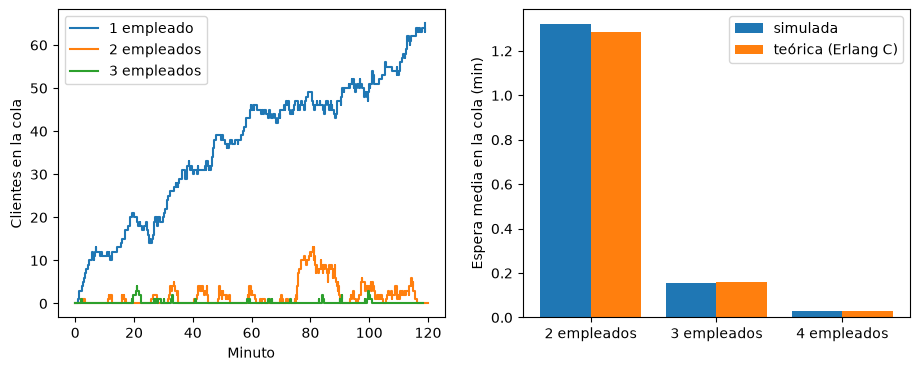

2 empleados: simulada 1.320 min, teórica 1.286 min
3 empleados: simulada 0.155 min, teórica 0.158 min
4 empleados: simulada 0.029 min, teórica 0.030 min


In [11]:
import simpy


def simular_oficina(llegada, servicio, empleados, minutos, semilla):
    rng = np.random.default_rng(semilla)
    env = simpy.Environment()
    oficina = simpy.Resource(env, capacity=empleados)
    esperas, cola = [], [(0, 0)]

    def cliente():
        llega = env.now
        with oficina.request() as turno:
            cola.append((env.now, len(oficina.queue)))
            yield turno
            esperas.append(env.now - llega)
            cola.append((env.now, len(oficina.queue)))
            yield env.timeout(rng.exponential(1 / servicio))

    def llegadas():
        while True:
            yield env.timeout(rng.exponential(1 / llegada))
            env.process(cliente())

    env.process(llegadas())
    env.run(until=minutos)
    esperas = np.array(esperas)
    return esperas[len(esperas) // 10:], cola


def espera_teorica(llegada, servicio, empleados):
    a, c = llegada / servicio, empleados
    ultimo = a**c / math.factorial(c) / (1 - a / c)
    erlang_c = ultimo / (sum(a**k / math.factorial(k) for k in range(c)) + ultimo)
    return erlang_c / (c * servicio - llegada)


esperas, _ = simular_oficina(0.8, 1, 1, 100_000, semilla=10)
teorica = 0.8 / (1 * (1 - 0.8))
print(f"M/M/1: espera media simulada {esperas.mean():.3f} min, teórica {teorica:.3f} min ({len(esperas)} clientes)")
assert abs(esperas.mean() - teorica) / teorica < 0.1
assert math.isclose(espera_teorica(0.8, 1, 1), teorica)

fig, (eje1, eje2) = plt.subplots(1, 2, figsize=(11, 4))
for c in (1, 2, 3):
    _, cola = simular_oficina(1.5, 1, c, 120, semilla=c)
    eje1.step(*zip(*cola), where="post", label=f"{c} empleado{'s' if c > 1 else ''}")
eje1.set_xlabel("Minuto")
eje1.set_ylabel("Clientes en la cola")
eje1.legend()

empleados = [2, 3, 4]
simuladas = [simular_oficina(1.5, 1, c, 50_000, semilla=20 + c)[0].mean() for c in empleados]
teoricas = [espera_teorica(1.5, 1, c) for c in empleados]
x = np.arange(len(empleados))
eje2.bar(x - 0.2, simuladas, width=0.4, label="simulada")
eje2.bar(x + 0.2, teoricas, width=0.4, label="teórica (Erlang C)")
eje2.set_xticks(x, [f"{c} empleados" for c in empleados])
eje2.set_ylabel("Espera media en la cola (min)")
eje2.legend()
plt.show()
for c, s, t in zip(empleados, simuladas, teoricas):
    print(f"{c} empleados: simulada {s:.3f} min, teórica {t:.3f} min")
    assert abs(s - t) < 0.1 * t + 0.02